<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/HybridQNN_IoTIntrusion_Bharathi2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum neural network (HQNN) for IoT intrusion detection: Bharathi et al. (2026) step by step

This notebook re-implements, runs and checks the method of

> Indira Bharathi, Veeramani Sonai and Sridevi S,
> "Quantum-driven enhanced machine learning algorithm for intrusion detection in Internet of things environment",
> *EPJ Quantum Technology* 13, 20 (2026). https://doi.org/10.1140/epjqt/s40507-026-00463-5

The paper publishes no code. Everything below is written from the method as the paper describes it (Sections 3 to 5).

**What the notebook does.** For three public intrusion-detection datasets (BoT-IoT features, ACI-IoT-2023, KDD Cup 99) it
(1) cleans the data and balances a small sample, (2) standardises and reduces it to **5 features with PCA**, (3) encodes
the features with a **5-qubit ZZ feature map**, (4) trains the paper's three quantum models, **QSVM** (quantum kernel),
**QNN** (feature map + RealAmplitudes ansatz) and the proposed **HQNN** (classical dense layers feeding a 5-qubit variational
circuit), and (5) trains the paper's three classical models (decision tree, SVM, DNN) on exactly the same 5 inputs. It then
reproduces the paper's Table 3 (accuracy, precision, recall, F1), the PCA-dimension study (Fig. 6), the repetition-code
noise study (Figs. 8 to 10), the ROC curves (Fig. 16) and the training-time comparison (Fig. 17), and ends with a verdict for
every claim it can test.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, and use *Runtime -> Run all*. The first cell installs the
pinned libraries (Colab may ask you to restart the session once; do so and run all cells again). No GPU, no IBM or AWS account
is needed.

**Runtime.** `FAST_MODE = True` (1,600-flow samples, 2 seeds) takes about 10 minutes on a laptop CPU.
`FAST_MODE = False` (4,000-flow samples, 3 seeds, longer training) takes roughly 40 minutes.

**What you get at the end.** Mean +- standard deviation over seeds for every model and dataset, ROC and confusion-matrix
figures, a paper-versus-notebook table with a verdict per number, and a section that reads the paper's own table critically
(several of its numbers cannot all be true at once).

## The paper in one page

**Problem.** Detect malicious traffic in IoT networks. Classical ML training time grows with data size; the authors propose
to compress the data with PCA and process it with quantum models.

**Decision.** Binary classification, *Normal* versus *Attack*, for each of three datasets.

**Pipeline (Figs. 1, 2, 7, 12).**
1. Label and standardise the data (scikit-learn `StandardScaler`), split 70 % train / 30 % test.
2. **PCA**, "k = 5" (found by sweeping k = 1 to 8, Fig. 6). The text selects the original features that carry the highest
   loading on the **first principal component** (Table 2 lists five original features per dataset), while Eq. 6 projects
   onto the top-k components. Both readings are run here.
3. **5-qubit ZZ feature map** (Hadamard, phase rotations, controlled-phase interactions; depth 2, Eqs. 9 to 11).
4. A **repetition code** after the encoding corrects bit-flip errors; success rate "97 %" for 80, 100 and 120 trials (Figs. 8 to 10).
5. Models: **QSVM** (fidelity kernel `|<phi(x)|phi(x')>|^2`, classical SVM on top), **QNN** (feature map, ansatz, measurement),
   **HQNN** (classical dense/convolution layers -> flatten -> fully connected -> variational quantum circuit with *angle
   embedding*, trainable rotations, a closed chain of CNOTs and a Pauli measurement, Eq. 17).
6. Classical comparison models: DT, SVM, DNN (hyper-parameters not given).

**Data (Table 1).** "BoT-IoT" 26 features, 1,048,575 rows; ACI-IoT 76 features, 1,048,575 rows; "ROUT-4-2023" 39 features,
494,021 rows (the text and all figures call the third dataset "KDD", and 494,021 is exactly the size of the 10 % KDD Cup 99 file).

**Claims checked here.**

| Claim | Paper |
|---|---|
| Table 3: training/testing accuracy, precision, recall and F1 of DT, SVM, DNN, QSVM, QNN, HQNN on three datasets | Table 3 |
| HQNN is the most accurate model (Section 5, abstract) | HQNN test accuracy 90.7 % (BoT), 92.8 % (ACI), 94.9 % (KDD) |
| k = 5 qubits is where accuracy saturates | Fig. 6 |
| The repetition code corrects errors with a 97 % success rate for 80, 100, 120 trials | Figs. 8 to 10 |
| HQNN trains faster than DT/SVM/DNN on the simulator (29 % to 72 % shorter) and on a quantum computer | Fig. 17 |
| Results on real quantum hardware (AWS Braket) | Section 5 |

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| BoT-IoT data | UNSW Canberra Bot-IoT, 26 features, 1,048,575 rows. The five features of Table 2 (`HH_jit_L0.1_*`, `H_L0.1_*`, `MI_dir_L0.1_*`) are **Kitsune-style damped-window statistics**, not UNSW Bot-IoT columns | Hugging Face `wassim249/ids-bot-iot`: 23 Kitsune-style features of the same family (`MI_dir`, `H`, `HH`, `HH_jit`, `HpHp`, decay L0.1), 21,318 rows in its validation split (the 2.1 M-row training split is available with `BOT_USE_FULL_TRAIN`). The file has only a 0/1 label; **attack = 0** is inferred from the packet-rate statistics (see section 1) |
| ACI-IoT data | ACI-IoT-2023 (IEEE DataPort, login required), 76 features, 1,048,575 rows | Hugging Face `knhn1004/aci-iot-2023-processed`: the same flows with 71 standardised CICFlowMeter features; multiclass test split, attack = any non-benign class |
| Third dataset | Table 1 says ROUT-4-2023 (RPL routing attacks), figures say KDD | **KDD Cup 99, 10 %** (494,021 rows in the original; Hugging Face `Pakapak/kdd_cup_1999`, 494,020 rows). ROUT-4-2023 has no public mirror; the text and figures use KDD features (`dst_host_srv_count`, `src_bytes`, ...) |
| Cleaning | scikit-learn labelling and standardisation | Inf/NaN rows dropped, **exact duplicate rows dropped** (otherwise copies of one flow land in both train and test; KDD falls from 494 k to 146 k rows), constant columns dropped, categorical KDD fields label-encoded (`# CHOICE:`) |
| Tail taming | not mentioned | signed `log1p` before standardisation (`LOG_TAME`, `# CHOICE:`): features like `HH_jit_L0.1_variance` reach 1e16 and flatten everything after min-max scaling. Section 12 measures its effect |
| Sample size | all rows | **class-balanced** random sample of `POOL_N` flows (1,600 or 4,000), because a CPU statevector simulation of kernels and circuits cannot take 10^6 rows (`# CHOICE:`) |
| Split | 70 % / 30 % | stratified 70 / 30, different draw per seed |
| PCA | k = 5, "first principal component features" (Table 2) and projection (Eq. 6) | main run: the **5 original features with the largest absolute loading on PC1**; ablation: projection on the first 5 components. Fitted on the training split only |
| Angle scaling | not stated | `MinMaxScaler((0, pi))` fitted on training data, test angles clipped |
| ZZ feature map | 5 qubits, depth 2 | `zz_feature_map(5, reps=2, entanglement="linear")`. For speed the states are computed by an exact NumPy implementation that is **checked against Qiskit's `Statevector`** (section 3) |
| QSVM | kernel `|<phi(x)|phi(x')>|^2` + SVM | exact statevector kernel into `SVC(kernel="precomputed")`; kernel bandwidth (angle scale) and `C` tuned on a validation part of the training split only; cross-checked against Qiskit `QSVC` + `FidelityStatevectorKernel` |
| QNN | feature map + ansatz + measurement, optimiser not given | ZZ map + `real_amplitudes(5, reps=3)`, observable Z on all five qubits (parity), squared-error loss, **COBYLA**. Trained with an exact evaluator that is **checked against Qiskit `EstimatorQNN`** |
| HQNN | dense/conv layers, angle embedding, rotations, closed CNOT chain, Pauli measurement | `Linear(5,32)-ReLU-Linear(32,5)`, `pi*tanh` to bound the angles, **AngleEmbedding(RX)**, 3 layers of `Rot` + closed CNOT chain, `<Y>` on each qubit (Eq. 17), `Linear(5,2)`. Adam lr 0.01, batch 64. Layer sizes, depth and optimiser are `# CHOICE:`; exact torch simulation checked against a PennyLane QNode |
| DT / SVM / DNN | no hyper-parameters | `DecisionTreeClassifier(max_depth=8)`, `SVC(rbf, C=1)`, `MLPClassifier((64,32))`; all on the same 5 angle-scaled inputs as the quantum models (`# CHOICE:`). A Random Forest and a Random Forest on all features are added as extra references |
| Repetition code | "after ZZ encoding"; success rate 97 % for 80/100/120 trials; noise model not given | 3-qubit bit-flip repetition code on each of the 5 data qubits, Qiskit Aer, bit-flip probability `p` per idle qubit (not given in the paper, so it is swept). Success = the feature-map circuit followed by its inverse returns to all zeros |
| Hardware | AWS Braket quantum computer | **not run** (no account); the hardware numbers cannot be checked |
| Seeds | not stated | `SEED = 42`, seeds 42, 43, ... for repeated runs; mean +- std reported |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
# The pip line runs on Colab (or wherever Qiskit / PennyLane are missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None or importlib.util.find_spec("pennylane") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "pennylane==0.45.1" pylatexenc huggingface_hub pyarrow
if importlib.util.find_spec("torch") is None:
    %pip install -q torch --index-url https://download.pytorch.org/whl/cpu
print("setup done (if Colab asks you to restart the session, do so and run all cells again)")

setup done (if Colab asks you to restart the session, do so and run all cells again)


In [2]:
# ---------------- configuration ----------------
FAST_MODE  = False          # True: class demo (about 10 minutes). False: larger samples, 3 seeds, longer training (about 40 minutes).

SEED       = 42             # CHOICE: the paper gives no seed
N_QUBITS   = 5              # paper: k = 5 principal components -> 5 qubits
TEST_SIZE  = 0.3            # paper: 70 % train / 30 % test
if FAST_MODE:
    POOL_N, N_SEEDS, HQNN_EPOCHS, QNN_MAXITER, KSWEEP_N, REP_REPEATS = 1600, 2, 30, 150, 800, 5
else:
    POOL_N, N_SEEDS, HQNN_EPOCHS, QNN_MAXITER, KSWEEP_N, REP_REPEATS = 4000, 3, 60, 300, 1500, 10
ZZ_REPS      = 2            # paper: circuit depth 2 (Eq. 11)
QNN_REPS     = 3            # CHOICE: RealAmplitudes repetitions of the QNN ansatz
HQNN_LAYERS  = 3            # CHOICE: variational layers of the HQNN circuit
HQNN_HIDDEN  = 32           # CHOICE: width of the classical layer in front of the circuit
HQNN_LR, HQNN_BATCH = 0.01, 64     # CHOICE: Adam, batch size
BANDWIDTHS   = [0.25, 0.5, 1.0, 2.0]   # CHOICE: QSVM angle scales tried on the validation split
C_GRID       = [1, 10]                 # CHOICE: SVM C values tried on the validation split
LOG_TAME     = True         # CHOICE: signed log1p before standardisation (section 12 measures its effect)
TOL_ACC      = 0.02         # a number is "reproduced" when it is within 2 accuracy points (0.02) of the paper
DATASETS     = ["BoT-IoT", "ACI-IoT", "KDD99"]

DATA_DIR     = "data"       # where downloads are cached (relative to the working directory)
LOCAL_FILES  = {"BoT-IoT": "", "ACI-IoT": "", "KDD99": ""}   # optional: path of your own copy (parquet/csv, same columns as the mirrors)
BOT_USE_FULL_TRAIN = False  # True: use the 2.1 M-row training parquet (306 MB) instead of the 21 k-row validation parquet
BOT_ATTACK_LABEL   = 0      # the mirror has only a 0/1 label; section 1 shows why 0 is taken as "attack"
ACI_FRAC     = 0.15         # share of the 343 MB ACI test split that is read (random rows) before balancing
IBM_TOKEN    = ""           # not used: the paper's hardware runs used AWS Braket, which is not reproducible here

In [3]:
import os, time, warnings, shutil, tarfile, math
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
import torch, torch.nn as nn, torch.nn.functional as F_
import qiskit, qiskit_machine_learning, qiskit_aer, pennylane as qml, sklearn
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.quantum_info import Operator, SparsePauliOp, Statevector
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.optimizers import COBYLA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 90)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__, "| qiskit-aer", qiskit_aer.__version__,
      "| pennylane", qml.__version__, "| torch", torch.__version__, "| sklearn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
print("FAST_MODE =", FAST_MODE, "| pool", POOL_N, "| seeds", N_SEEDS, "| HQNN epochs", HQNN_EPOCHS, "| QNN COBYLA iterations", QNN_MAXITER)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer 0.17.2 | pennylane 0.45.1 | torch 2.14.1+cpu | sklearn 1.9.1 | numpy 2.5.4 | pandas 3.0.6
FAST_MODE = False | pool 4000 | seeds 3 | HQNN epochs 60 | QNN COBYLA iterations 300


## 1. The three datasets

Each loader returns a table of numeric features `X` and a 0/1 target `y` (1 = attack). Downloads are cached in `DATA_DIR`.

* **BoT-IoT** (`wassim249/ids-bot-iot`): 23 damped-window packet statistics (`MI_dir_L0.1_weight`, `H_L0.1_mean`, `HH_jit_L0.1_variance`, ...)
  and a 0/1 `label`. The five features the paper lists in Table 2 are all in this file. The mirror does not say which label is
  the attack, so the next cell compares the packet-rate statistic `MI_dir_L0.1_weight` of the two classes: flooding attacks give
  very large packet counts in the 0.1-second window, so the class with the huge median is the attack.
* **ACI-IoT-2023** (`knhn1004/aci-iot-2023-processed`): CICFlowMeter flow statistics of an IoT testbed with ten attack classes
  (floods, scans, dictionary attack, slowloris). The 467 MB archive is downloaded once, the multiclass test split (343 MB) is
  streamed out and a random `ACI_FRAC` of its rows is kept.
* **KDD Cup 99, 10 %** (`Pakapak/kdd_cup_1999`): the classical 41-feature connection records; `normal` versus all attack types.

In [4]:
def _hf(repo, fname):
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo, fname, repo_type="dataset", local_dir=DATA_DIR)

def load_bot():
    path = LOCAL_FILES["BoT-IoT"] or _hf("wassim249/ids-bot-iot", "data/train-00000-of-00001.parquet" if BOT_USE_FULL_TRAIN else "data/validation-00000-of-00001.parquet")
    d = pd.read_parquet(path).drop(columns="__index_level_0__", errors="ignore")
    y = (d.pop("label") == BOT_ATTACK_LABEL).astype(int)
    return d, y

def load_aci():
    cache = os.path.join(DATA_DIR, "aci_sample.csv")
    if LOCAL_FILES["ACI-IoT"]:
        src = LOCAL_FILES["ACI-IoT"]
    else:
        src = os.path.join(DATA_DIR, "aci_test_full.csv")
        if not os.path.exists(cache) and not os.path.exists(src):
            tgz = _hf("knhn1004/aci-iot-2023-processed", "datasets.tar.gz")          # 467 MB, cached
            with tarfile.open(tgz, "r:gz") as tf, open(src, "wb") as dst:           # stream only the member we need
                shutil.copyfileobj(tf.extractfile("datasets/processed/test.csv"), dst)
    if not os.path.exists(cache):
        parts = [ch.sample(frac=ACI_FRAC, random_state=SEED) for ch in pd.read_csv(src, chunksize=200_000)]
        pd.concat(parts, ignore_index=True).to_csv(cache, index=False)
        if not LOCAL_FILES["ACI-IoT"]: os.remove(src)                                # keep the cache small
    d = pd.read_csv(cache)
    y = (d.pop("Label") != 0).astype(int)                                           # 0 = Benign, 1..10 = attack classes
    return d, y

def load_kdd():
    try:
        d = pd.read_csv(LOCAL_FILES["KDD99"] or _hf("Pakapak/kdd_cup_1999", "kdd_df.csv"))
        y = (d.pop("attack_type") != "normal").astype(int); d = d.drop(columns="target")
    except Exception as e:                                                          # fallback: scikit-learn's own copy of the 10 % file
        print("Hugging Face mirror failed (", e, ") -> sklearn.fetch_kddcup99")
        from sklearn.datasets import fetch_kddcup99
        d = fetch_kddcup99(percent10=True, as_frame=True, data_home=DATA_DIR).frame
        y = (~d.pop("labels").astype(str).str.contains("normal")).astype(int)
    for c in ["protocol_type", "service", "flag"]:                                  # CHOICE: label-encode the 3 categorical fields
        d[c] = d[c].astype(str).astype("category").cat.codes
    return d, y

def clean(X, y):
    X = X.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    ok = X.notna().all(axis=1); X, y = X[ok], y[ok]
    keep = ~X.duplicated(); X, y = X[keep], y[keep]                                 # exact duplicates would leak between train and test
    X = X.loc[:, X.nunique() > 1]                                                   # constant columns carry nothing
    return X.reset_index(drop=True), y.reset_index(drop=True)

LOADERS = {"BoT-IoT": load_bot, "ACI-IoT": load_aci, "KDD99": load_kdd}
RAW, SUMMARY = {}, []
for name in DATASETS:
    X0, y0 = LOADERS[name]()
    n0 = len(X0)
    RAW[name] = clean(X0, y0)
    X, y = RAW[name]
    SUMMARY.append({"dataset": name, "rows read": n0, "rows after cleaning": len(X), "features": X.shape[1], "attack share": round(float(y.mean()), 3)})
display(pd.DataFrame(SUMMARY))

,dataset,rows read,rows after cleaning,features,attack share
0,BoT-IoT,21318,21318,23,0.767
1,ACI-IoT,35117,35117,71,0.739
2,KDD99,494020,145583,39,0.397


In [5]:
# Which BoT-IoT label is the attack? Flooding gives huge packet counts in the 0.1 s window.
Xb, yb_attack = RAW["BoT-IoT"]
chk = Xb[["MI_dir_L0.1_weight", "HH_L0.1_weight", "HpHp_L0.1_weight"]].groupby(yb_attack.map({1: "label taken as attack", 0: "label taken as normal"})).median()
display(chk)
print("-> the class taken as attack has far larger packet counts per window, as flooding traffic should (assumption stated in the table above)")

,MI_dir_L0.1_weight,HH_L0.1_weight,HpHp_L0.1_weight
label,,,
label taken as attack,5689.640092,2095.121769,1.000000
label taken as normal,7.046580,2.428513,1.947799


-> the class taken as attack has far larger packet counts per window, as flooding traffic should (assumption stated in the table above)


## 2. Balanced sample, standardisation, PCA and angle scaling

`prepare(name, seed)` does the paper's preprocessing for one run. **Every transform is fitted on the training split only.**

1. Draw a class-balanced pool of `POOL_N` flows (our computational limit), stratified 70/30 split.
2. Signed `log1p` (optional, `LOG_TAME`), then `StandardScaler` (the paper's Eq. 3).
3. PCA on the training split. `variant="pc1_top5"` keeps the five original features with the largest |loading| on the
   first principal component (what Table 2 and the conclusion describe); `variant="pca_proj"` projects on the first five
   components (Eq. 6).
4. `MinMaxScaler((0, pi))` so every value is a valid rotation angle; test values are clipped to `[0, pi]`.

The paper's Table 2 names the five selected features; the cell below prints ours next to them.

In [6]:
def tame(A, log=None):
    log = LOG_TAME if log is None else log
    return np.sign(A) * np.log1p(np.abs(A)) if log else A

def prepare(name, seed, variant="pc1_top5", k=N_QUBITS, pool_n=None, log=None):
    X, y = RAW[name]
    r = np.random.default_rng(seed)
    per = min((pool_n or POOL_N) // 2, int(y.sum()), int((1 - y).sum()))
    idx = np.r_[r.choice(np.where(y.values == 1)[0], per, replace=False), r.choice(np.where(y.values == 0)[0], per, replace=False)]
    A, yy = tame(X.values[idx].astype(float), log), y.values[idx]
    tr, te = train_test_split(np.arange(len(idx)), test_size=TEST_SIZE, stratify=yy, random_state=seed)
    Z = StandardScaler().fit(A[tr]).transform(A)                                    # fitted on the training rows only
    pca = PCA(random_state=seed).fit(Z[tr])
    if variant == "pc1_top5":
        cols = np.argsort(-np.abs(pca.components_[0]))[:k]; Fe, names = Z[:, cols], list(X.columns[cols])
    else:
        Fe, names = PCA(k, random_state=seed).fit(Z[tr]).transform(Z), [f"PC{i+1}" for i in range(k)]
    Fe = np.clip(MinMaxScaler((0, np.pi)).fit(Fe[tr]).transform(Fe), 0, np.pi)
    return dict(F=Fe, Z=Z, y=yy, tr=tr, te=te, names=names, evr=pca.explained_variance_ratio_)

PAPER_FEATURES = {   # Table 2
    "BoT-IoT": ["HH_jit_L0.1_variance", "HH_jit_L0.1_mean", "H_L0.1_variance", "MI_dir_L0.1_variance", "H_L0.1_weight"],
    "ACI-IoT": ["Flow Duration", "Flow IAT Total", "Fwd IAT Max", "Flow IAT Max", "Fwd IAT Mean"],
    "KDD99":   ["dst_host_srv_count", "srv_count", "count", "duration", "src_bytes"]}
rows = []
for name in DATASETS:
    D = prepare(name, SEED)
    rows.append({"dataset": name, "train/test": f"{len(D['tr'])}/{len(D['te'])}", "PC1 explains": f"{D['evr'][0]:.0%}",
                 "our 5 features (largest |loading| on PC1)": ", ".join(D["names"]),
                 "paper Table 2": ", ".join(PAPER_FEATURES[name]), "overlap": len(set(D["names"]) & set(PAPER_FEATURES[name]))})
display(pd.DataFrame(rows))

,dataset,train/test,PC1 explains,our 5 features (largest |loading| on PC1),paper Table 2,overlap
0,BoT-IoT,2800/1200,36%,"HH_L0.1_mean, HpHp_L0.1_mean, HH_L0.1_magnitude, HpHp_L0.1_magnitude, MI_dir_L0.1_mean","HH_jit_L0.1_variance, HH_jit_L0.1_mean, H_L0.1_variance, MI_dir_L0.1_variance, H_L0.1_...",0
1,ACI-IoT,2800/1200,22%,"Packet Length Max, Packet Length Mean, Packet Length Std, Packet Length Variance, Aver...","Flow Duration, Flow IAT Total, Fwd IAT Max, Flow IAT Max, Fwd IAT Mean",0
2,KDD99,2800/1200,28%,"same_srv_rate, dst_host_same_srv_rate, src_bytes, count, dst_bytes","dst_host_srv_count, srv_count, count, duration, src_bytes",2


## 3. The 5-qubit ZZ feature map

The paper's feature map (Fig. 7, Eqs. 9 to 11) is Qiskit's `ZZFeatureMap`: per repetition a Hadamard on every qubit, a phase
rotation `P(2 x_i)` on every qubit and, for neighbouring qubits, `CX - P(2 (pi - x_i)(pi - x_j)) - CX`. Depth 2 means two repetitions.

Because the circuit is a layer of Hadamards followed by a *diagonal* phase, the final state of a whole table of rows can be
computed with one matrix product, which makes the kernel and the QNN training thousands of times faster than building a circuit per
row. `zz_states` does exactly that, and the cell below proves it equals Qiskit's `Statevector` of `zz_feature_map` for random angles
(2, 5 and 8 qubits). Qubit 0 is the least significant bit, as in Qiskit.

2 qubits: max |amplitude difference| = 6.28e-16 | min overlap with Qiskit's state = 1.000000000000
5 qubits: max |amplitude difference| = 1.19e-15 | min overlap with Qiskit's state = 1.000000000000
8 qubits: max |amplitude difference| = 1.95e-15 | min overlap with Qiskit's state = 1.000000000000


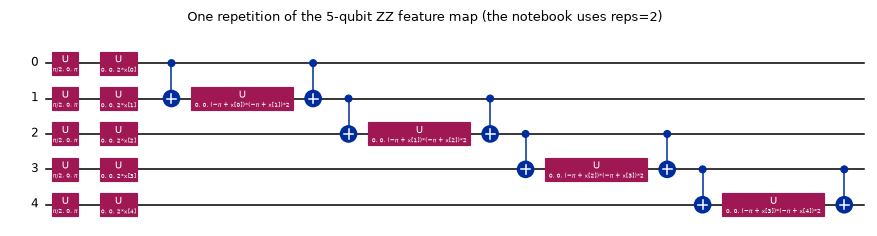

In [7]:
def _walsh(n):
    H = np.array([[1.0, 1.0], [1.0, -1.0]]) / np.sqrt(2); M = np.array([[1.0]])
    for _ in range(n): M = np.kron(H, M)
    return M

def zz_states(X, reps=None):
    # Exact statevectors of zz_feature_map(n, reps, 'linear') for every row of X, shape (N, 2**n).
    reps = ZZ_REPS if reps is None else reps
    N, n = X.shape
    b = (np.arange(2 ** n)[:, None] >> np.arange(n)[None, :]) & 1               # bit i of the basis index = qubit i
    ph = 2.0 * X @ b.T                                                           # P(2 x_i) on every qubit
    for i in range(n - 1):                                                       # CX - P(2 (pi-x_i)(pi-x_j)) - CX on neighbours
        ph = ph + (2.0 * (np.pi - X[:, i]) * (np.pi - X[:, i + 1]))[:, None] * (b[:, i] ^ b[:, i + 1])[None, :]
    D, Hm = np.exp(1j * ph), _walsh(n)
    psi = np.zeros((N, 2 ** n), complex); psi[:, 0] = 1.0
    for _ in range(reps): psi = (psi @ Hm.T) * D                                 # Hadamards, then the diagonal phase, per repetition
    return psi

def fidelity_kernel(Sa, Sb): return np.abs(Sa.conj() @ Sb.T) ** 2

for n in (2, 5, 8):
    fm = zz_feature_map(n, reps=ZZ_REPS, entanglement="linear")
    Xt = np.random.default_rng(1).uniform(0, np.pi, (6, n))
    Q = np.array([Statevector(fm.assign_parameters(x)).data for x in Xt])
    err = np.abs(zz_states(Xt)[:, :] - Q).max()
    ovl = np.abs(np.einsum("ij,ij->i", zz_states(Xt).conj(), Q))                 # |<mine|qiskit>| must be 1 (global phase free)
    print(f"{n} qubits: max |amplitude difference| = {err:.2e} | min overlap with Qiskit's state = {ovl.min():.12f}")
    assert np.allclose(ovl, 1.0, atol=1e-9)

fm1 = zz_feature_map(N_QUBITS, reps=1, entanglement="linear")
fig_fm = fm1.decompose().draw("mpl", scale=0.55, fold=-1)
fig_fm.suptitle("One repetition of the 5-qubit ZZ feature map (the notebook uses reps=2)", fontsize=9)
display(fig_fm)

## 4. Metrics and the classical models

Every model returns the same record: predictions on the training and the test rows, a continuous score (for the ROC curve) and
the wall-clock time of fitting plus predicting. Metrics follow Table 3 of the paper: training accuracy, testing accuracy, accuracy
error (1 - testing accuracy), precision, recall, F1 (attack is the positive class) and, for Fig. 16, ROC AUC.

The three classical models of the paper, **DT**, **SVM** and **DNN**, are trained on exactly the same 5 angle-scaled inputs as the
quantum models. Two extra references are added: a Random Forest on the same 5 inputs and a Random Forest on *all* standardised
features (what a classical detector could do without the 5-feature limit that the qubit count imposes).

In [8]:
RESULTS, STORE = [], {}          # RESULTS: one row per (dataset, seed, model); STORE: scores/predictions kept for plots

def record(ds, seed, model, y, tr, te, ptr, pte, score, t, extra=None):
    row = dict(dataset=ds, seed=seed, model=model,
               train_acc=accuracy_score(y[tr], ptr), test_acc=accuracy_score(y[te], pte),
               precision=precision_score(y[te], pte, zero_division=0), recall=recall_score(y[te], pte, zero_division=0),
               f1=f1_score(y[te], pte, zero_division=0), auc=roc_auc_score(y[te], score), time_s=t)
    RESULTS.append(row)
    STORE.setdefault((ds, model), []).append(dict(seed=seed, y=y[te], score=score, pred=pte))
    return row

def run_classical(ds, seed, D):
    F, Z, y, tr, te = D["F"], D["Z"], D["y"], D["tr"], D["te"]
    specs = {"DT": (DecisionTreeClassifier(max_depth=8, random_state=seed), F),                       # CHOICE: max_depth
             "SVM": (SVC(kernel="rbf", C=1.0, random_state=seed), F),
             "DNN": (MLPClassifier((64, 32), max_iter=300, random_state=seed), F),                    # CHOICE: architecture
             "RF (extra)": (RandomForestClassifier(200, random_state=seed, n_jobs=2), F),
             "RF all features (extra)": (RandomForestClassifier(200, random_state=seed, n_jobs=2), Z)}
    for name, (m, X) in specs.items():
        t0 = time.perf_counter(); m.fit(X[tr], y[tr]); pte = m.predict(X[te]); t = time.perf_counter() - t0
        s = m.decision_function(X[te]) if hasattr(m, "decision_function") else m.predict_proba(X[te])[:, 1]
        record(ds, seed, name, y, tr, te, m.predict(X[tr]), pte, s, t)

## 5. QSVM: the quantum kernel

The kernel is the squared overlap of the two encoded states, `k(x, x') = |<phi(x)|phi(x')>|^2` (Eq. 8). With the exact states
this is one matrix product. The Gram matrix goes into a classical `SVC(kernel="precomputed")`, which is exactly what the paper
and Qiskit's `QSVC` do.

Two settings are not given by the paper and are chosen on a **validation quarter of the training rows only**: the kernel
*bandwidth* (the angles are multiplied by a scale `g` before encoding) and the SVM penalty `C`.

The cell ends with a check against Qiskit's own `QSVC` + `FidelityStatevectorKernel` on 60 training and 30 test rows.

In [9]:
def fit_qsvm(F, y, tr, te, seed):
    # Returns train predictions, test predictions, test scores, time, chosen (bandwidth, C).
    t0 = time.perf_counter()
    itr, iva = train_test_split(np.arange(len(tr)), test_size=0.25, stratify=y[tr], random_state=seed)   # validation inside the training rows
    best, S_cache = (-1.0, None), {}
    for g in BANDWIDTHS:
        S = zz_states(g * F[tr]); S_cache[g] = S; K = fidelity_kernel(S, S)
        for C in C_GRID:
            m = SVC(kernel="precomputed", C=C).fit(K[np.ix_(itr, itr)], y[tr][itr])
            a = m.score(K[np.ix_(iva, itr)], y[tr][iva])
            if a > best[0]: best = (a, (g, C))
    g, C = best[1]
    Str, Ste = S_cache[g], zz_states(g * F[te]); Ktr = fidelity_kernel(Str, Str)
    m = SVC(kernel="precomputed", C=C).fit(Ktr, y[tr])
    Kte = fidelity_kernel(Ste, Str)
    return m.predict(Ktr), m.predict(Kte), m.decision_function(Kte), time.perf_counter() - t0, (g, C)

# ---- cross-check with Qiskit's QSVC on a small subset ----
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.algorithms import QSVC
D0 = prepare("BoT-IoT", SEED)
a_idx, b_idx = D0["tr"][:60], D0["te"][:30]
fm_q = zz_feature_map(N_QUBITS, reps=ZZ_REPS, entanglement="linear")
qk = FidelityStatevectorKernel(feature_map=fm_q)
K_qiskit = qk.evaluate(D0["F"][b_idx], D0["F"][a_idx])
K_mine = fidelity_kernel(zz_states(D0["F"][b_idx]), zz_states(D0["F"][a_idx]))
print("max |kernel difference| (Qiskit FidelityStatevectorKernel vs ours):", float(np.abs(K_qiskit - K_mine).max()))
assert np.allclose(K_qiskit, K_mine, atol=1e-8)
qsvc = QSVC(quantum_kernel=qk, C=1.0).fit(D0["F"][a_idx], D0["y"][a_idx])
Sa = zz_states(D0["F"][a_idx]); mine = SVC(kernel="precomputed", C=1.0).fit(fidelity_kernel(Sa, Sa), D0["y"][a_idx])
agree = (qsvc.predict(D0["F"][b_idx]) == mine.predict(K_mine)).mean()
print(f"QSVC (Qiskit) and SVC(precomputed) predictions agree on {agree:.0%} of the 30 test rows")

max |kernel difference| (Qiskit FidelityStatevectorKernel vs ours): 3.1086244689504383e-15


QSVC (Qiskit) and SVC(precomputed) predictions agree on 100% of the 30 test rows


## 6. QNN: feature map + ansatz + measurement

The QNN of Section 4.8 is the ZZ feature map, a trainable ansatz (`real_amplitudes`, 5 qubits, 3 repetitions = 20 weights) and a
measurement. The output is the expectation of the parity operator `Z x Z x Z x Z x Z`, a number in [-1, 1]; the label is its
sign. Training minimises the squared error to the +-1 labels with the gradient-free **COBYLA** optimiser, as in Qiskit's
`NeuralNetworkClassifier` tutorials.

Qiskit's `EstimatorQNN` evaluates one circuit per row, which is slow for COBYLA's hundreds of evaluations. Since the feature-map
states are fixed, the same output is `sum_b sign(b) |(U(w) psi(x))_b|^2` with the ansatz unitary `U(w)`. The cell checks this
evaluator against `EstimatorQNN.forward` to numerical precision before using it.

In [10]:
from qiskit_machine_learning.neural_networks import EstimatorQNN
ANSATZ = real_amplitudes(N_QUBITS, reps=QNN_REPS)
PARITY = 1 - 2 * np.array([bin(i).count("1") % 2 for i in range(2 ** N_QUBITS)])        # eigenvalue of Z x Z x Z x Z x Z

def qnn_out(S, w):
    U = Operator(ANSATZ.assign_parameters(w)).data
    return (np.abs(S @ U.T) ** 2) @ PARITY

def fit_qnn(F, y, tr, te, seed):
    t0 = time.perf_counter()
    r = np.random.default_rng(seed); w0 = r.uniform(0, 2 * np.pi, ANSATZ.num_parameters)
    Str, Ste = zz_states(F[tr]), zz_states(F[te]); ypm = 2.0 * y[tr] - 1
    hist = []
    def loss(w):
        v = float(np.mean((qnn_out(Str, w) - ypm) ** 2)); hist.append(v); return v
    w = COBYLA(maxiter=QNN_MAXITER).minimize(loss, w0).x
    f_tr, f_te = qnn_out(Str, w), qnn_out(Ste, w)
    return (f_tr > 0).astype(int), (f_te > 0).astype(int), f_te, time.perf_counter() - t0, hist

# ---- cross-check with Qiskit's EstimatorQNN ----
circ = fm_q.compose(ANSATZ)
qnn_qiskit = EstimatorQNN(circuit=circ, input_params=fm_q.parameters, weight_params=ANSATZ.parameters,
                          observables=SparsePauliOp.from_list([("Z" * N_QUBITS, 1.0)]))
w_chk = np.random.default_rng(3).uniform(0, 2 * np.pi, ANSATZ.num_parameters)
x_chk = D0["F"][b_idx][:8]
ref = qnn_qiskit.forward(x_chk, w_chk).ravel(); mine_out = qnn_out(zz_states(x_chk), w_chk)
print("max |EstimatorQNN - our evaluator| on 8 rows:", float(np.abs(ref - mine_out).max()))
assert np.allclose(ref, mine_out, atol=1e-8)
print("QNN weights:", ANSATZ.num_parameters, "| ansatz depth", ANSATZ.decompose().depth())

max |EstimatorQNN - our evaluator| on 8 rows: 8.049116928532385e-16
QNN weights: 20 | ansatz depth 12


## 7. HQNN: the proposed hybrid network

Section 4.9 and Fig. 12: classical layers, then a variational quantum circuit, then a measurement whose results feed the output.
The circuit has three parts (Eq. 17): **angle embedding** (`RX` on each qubit by the incoming feature), **variational gates**
(a trainable single-qubit rotation per qubit followed by a *closed chain* of CNOTs, repeated `HQNN_LAYERS` times) and a **Pauli-Y
measurement** on every qubit.

Our network: `Linear(5, 32) - ReLU - Linear(32, 5)` bounds the output to angles with `pi * tanh`, the circuit returns five `<Y>`
values in [-1, 1], and `Linear(5, 2)` + softmax gives the class. The circuit is defined as a PennyLane QNode (the reference).
For training we use an exact batched torch simulation of the same gates, which gives the same numbers (checked below to 1e-6)
and is fast enough to train for many epochs. A **control model** replaces the circuit by `tanh` of the same five numbers: if the
control matches the HQNN, the quantum circuit is not what produces the accuracy.

In [11]:
NQ, L = N_QUBITS, HQNN_LAYERS
dev = qml.device("default.qubit", wires=NQ)

def variational(w):
    # w has shape (L, NQ, 3): one general rotation per qubit, then a closed chain of CNOTs, per layer.
    for l in range(L):
        for q in range(NQ): qml.Rot(w[l, q, 0], w[l, q, 1], w[l, q, 2], wires=q)
        for q in range(NQ): qml.CNOT(wires=[q, (q + 1) % NQ])

@qml.qnode(dev, interface="torch", diff_method="backprop")
def hqnn_qnode(x, w):
    qml.AngleEmbedding(x, wires=range(NQ), rotation="X")                  # embedding: RX(x_i) on qubit i
    variational(w)
    return [qml.expval(qml.PauliY(q)) for q in range(NQ)]                 # Pauli-Y read-out (Eq. 17)

w_demo = torch.rand(L, NQ, 3) * 2 * np.pi
ops = qml.tape.make_qscript(variational)(w_demo).operations
print(f"trainable rotations: {sum(o.name == 'Rot' for o in ops)} (x3 angles) | CNOTs: {sum(o.name == 'CNOT' for o in ops)}  (closed chain on {NQ} qubits)")
print(qml.draw(hqnn_qnode, decimals=1, max_length=140)(torch.rand(NQ), w_demo))

# ---- exact batched torch simulation of the same circuit (used for training) ----
def _apply1(psi, M, q):                                                    # single-qubit gate M on qubit q; M is (2,2) or (B,2,2)
    t = psi.movedim(1 + q, -1)
    t = torch.einsum("ij,b...j->b...i", M, t) if M.dim() == 2 else torch.einsum("bij,b...j->b...i", M, t)
    return t.movedim(-1, 1 + q)

def _cnot(psi, c, t):
    s = psi.movedim((1 + c, 1 + t), (1, 2))
    s = torch.stack([s[:, 0], s[:, 1].flip(1)], dim=1)                      # flip the target where the control is 1
    return s.movedim((1, 2), (1 + c, 1 + t))

def _rot_matrix(phi, theta, omega):                                         # PennyLane qml.Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    e = lambda a: torch.polar(torch.ones_like(a), a)
    return torch.stack([torch.stack([e(-(phi + omega) / 2) * c, -e((phi - omega) / 2) * s]),
                        torch.stack([e(-(phi - omega) / 2) * s, e((phi + omega) / 2) * c])])

def vqc_exact(x, w):
    x, w = x.double(), w.double(); B = x.shape[0]
    psi = torch.zeros((B,) + (2,) * NQ, dtype=torch.complex128); psi[(slice(None),) + (0,) * NQ] = 1
    for q in range(NQ):                                                     # AngleEmbedding(rotation="X")
        c, s = torch.cos(x[:, q] / 2).to(torch.complex128), torch.sin(x[:, q] / 2).to(torch.complex128)
        M = torch.stack([torch.stack([c, -1j * s], 1), torch.stack([-1j * s, c], 1)], 1)
        psi = _apply1(psi, M, q)
    for l in range(L):
        for q in range(NQ): psi = _apply1(psi, _rot_matrix(w[l, q, 0], w[l, q, 1], w[l, q, 2]), q)
        for q in range(NQ): psi = _cnot(psi, q, (q + 1) % NQ)
    out = []
    for q in range(NQ):                                                     # <Y_q> = 2 Im sum conj(psi_0) psi_1
        t = psi.movedim(1 + q, -1)
        out.append(2 * (t[..., 0].conj() * t[..., 1]).imag.reshape(B, -1).sum(1))
    return torch.stack(out, 1).float()

x_demo = torch.rand(6, NQ) * np.pi
ref = torch.stack([torch.stack(hqnn_qnode(x, w_demo)) for x in x_demo]).float()
print("max |PennyLane QNode - exact torch simulation| =", float((ref - vqc_exact(x_demo, w_demo)).abs().max()))
assert torch.allclose(ref, vqc_exact(x_demo, w_demo), atol=1e-5)

trainable rotations: 15 (x3 angles) | CNOTs: 15  (closed chain on 5 qubits)
0: ─╭AngleEmbedding(M0)──Rot(5.5,5.7,2.4)─╭●──────────╭X──Rot(2.7,5.6,3.6)─╭●──────────╭X──Rot(6.0,0.5,5.6)─╭●──────────╭X─┤  <Y>
1: ─├AngleEmbedding(M0)──Rot(6.0,2.5,3.8)─╰X─╭●───────│───Rot(1.7,3.9,1.7)─╰X─╭●───────│───Rot(3.7,2.1,5.1)─╰X─╭●───────│──┤  <Y>
2: ─├AngleEmbedding(M0)──Rot(1.6,5.0,5.9)────╰X─╭●────│───Rot(2.8,1.9,5.2)────╰X─╭●────│───Rot(3.6,5.7,3.5)────╰X─╭●────│──┤  <Y>
3: ─├AngleEmbedding(M0)──Rot(0.8,5.9,3.7)───────╰X─╭●─│───Rot(0.7,1.7,2.3)───────╰X─╭●─│───Rot(2.2,4.0,2.3)───────╰X─╭●─│──┤  <Y>
4: ─╰AngleEmbedding(M0)──Rot(5.5,3.6,4.7)──────────╰X─╰●──Rot(1.3,3.4,0.0)──────────╰X─╰●──Rot(4.5,5.9,5.0)──────────╰X─╰●─┤  <Y>

M0 = 
tensor([0.2814, 0.7886, 0.5895, 0.7539, 0.1952])


max |PennyLane QNode - exact torch simulation| = 1.4901161193847656e-07


In [12]:
class HQNN(nn.Module):
    # quantum=True: the paper's HQNN. quantum=False: control with tanh instead of the circuit.
    def __init__(s, quantum=True):
        super().__init__(); s.quantum = quantum
        s.front = nn.Sequential(nn.Linear(NQ, HQNN_HIDDEN), nn.ReLU(), nn.Linear(HQNN_HIDDEN, NQ))
        s.w = nn.Parameter(torch.rand(L, NQ, 3) * 2 * np.pi) if quantum else None
        s.out = nn.Linear(NQ, 2)
    def forward(s, x):
        h = s.front(x)
        z = vqc_exact(np.pi * torch.tanh(h), s.w) if s.quantum else torch.tanh(h)       # CHOICE: bound the angles with pi*tanh
        return s.out(z)

def fit_hqnn(F, y, tr, te, seed, quantum=True):
    torch.manual_seed(seed); np.random.seed(seed)
    net = HQNN(quantum); opt = torch.optim.Adam(net.parameters(), lr=HQNN_LR)
    Xt, yt = torch.tensor(F[tr], dtype=torch.float32), torch.tensor(y[tr])
    hist, t0 = [], time.perf_counter()
    for ep in range(HQNN_EPOCHS):
        net.train(); perm = torch.randperm(len(tr)); tot = 0.0
        for i in range(0, len(tr), HQNN_BATCH):
            b = perm[i:i + HQNN_BATCH]; opt.zero_grad()
            loss = F_.cross_entropy(net(Xt[b]), yt[b]); loss.backward(); opt.step(); tot += loss.item() * len(b)
        hist.append(tot / len(tr))
    net.eval()
    with torch.no_grad():
        lo_tr = net(Xt); lo_te = net(torch.tensor(F[te], dtype=torch.float32))
    t = time.perf_counter() - t0
    return lo_tr.argmax(1).numpy(), lo_te.argmax(1).numpy(), torch.softmax(lo_te, 1)[:, 1].numpy(), t, hist


print("parameters  HQNN:", sum(p.numel() for p in HQNN(True).parameters()), "| control:", sum(p.numel() for p in HQNN(False).parameters()))

parameters  HQNN: 414 | control: 369


## 8. Running everything

For every dataset and every seed: draw the balanced pool, split, fit the preprocessing on the training rows, then train the
classical models, QSVM, QNN, HQNN and the control. This is the cell that takes most of the time.

In [13]:
CURVES, CHOSEN, MODEL_ORDER = {}, [], ["DT", "SVM", "DNN", "QSVM", "QNN", "HQNN"]
t_all = time.time()
for ds in DATASETS:
    for si in range(N_SEEDS):
        seed = SEED + si
        D = prepare(ds, seed)
        F, y, tr, te = D["F"], D["y"], D["tr"], D["te"]
        run_classical(ds, seed, D)
        p1, p2, s, t, bc = fit_qsvm(F, y, tr, te, seed); record(ds, seed, "QSVM", y, tr, te, p1, p2, s, t); CHOSEN.append((ds, seed) + bc)
        p1, p2, s, t, h = fit_qnn(F, y, tr, te, seed); record(ds, seed, "QNN", y, tr, te, p1, p2, s, t); CURVES[(ds, seed, "QNN")] = h
        p1, p2, s, t, h = fit_hqnn(F, y, tr, te, seed, True); record(ds, seed, "HQNN", y, tr, te, p1, p2, s, t); CURVES[(ds, seed, "HQNN")] = h
        p1, p2, s, t, h = fit_hqnn(F, y, tr, te, seed, False); record(ds, seed, "HQNN control (no circuit)", y, tr, te, p1, p2, s, t); CURVES[(ds, seed, "control")] = h
        last = {r["model"]: r for r in RESULTS[-9:]}
        print(f"{ds:8s} seed {seed}: " + " | ".join(f"{m} {last[m]['test_acc']:.3f}" for m in MODEL_ORDER + ["HQNN control (no circuit)"])
              + f"   [{time.time() - t_all:.0f}s]", flush=True)
res = pd.DataFrame(RESULTS)
print("QSVM chosen (dataset, seed, bandwidth, C):", CHOSEN)

BoT-IoT  seed 42: DT 0.993 | SVM 0.988 | DNN 0.993 | QSVM 0.988 | QNN 0.884 | HQNN 0.993 | HQNN control (no circuit) 0.993   [214s]


BoT-IoT  seed 43: DT 0.988 | SVM 0.966 | DNN 0.984 | QSVM 0.979 | QNN 0.905 | HQNN 0.989 | HQNN control (no circuit) 0.974   [435s]


BoT-IoT  seed 44: DT 0.992 | SVM 0.977 | DNN 0.980 | QSVM 0.979 | QNN 0.909 | HQNN 0.987 | HQNN control (no circuit) 0.982   [685s]


ACI-IoT  seed 42: DT 0.922 | SVM 0.810 | DNN 0.922 | QSVM 0.923 | QNN 0.762 | HQNN 0.912 | HQNN control (no circuit) 0.912   [876s]


ACI-IoT  seed 43: DT 0.913 | SVM 0.811 | DNN 0.897 | QSVM 0.906 | QNN 0.780 | HQNN 0.906 | HQNN control (no circuit) 0.907   [1061s]


ACI-IoT  seed 44: DT 0.910 | SVM 0.818 | DNN 0.900 | QSVM 0.906 | QNN 0.802 | HQNN 0.902 | HQNN control (no circuit) 0.884   [1234s]


KDD99    seed 42: DT 0.983 | SVM 0.981 | DNN 0.989 | QSVM 0.987 | QNN 0.840 | HQNN 0.984 | HQNN control (no circuit) 0.988   [1389s]


KDD99    seed 43: DT 0.987 | SVM 0.978 | DNN 0.984 | QSVM 0.983 | QNN 0.888 | HQNN 0.978 | HQNN control (no circuit) 0.983   [1581s]


KDD99    seed 44: DT 0.998 | SVM 0.983 | DNN 0.992 | QSVM 0.994 | QNN 0.823 | HQNN 0.994 | HQNN control (no circuit) 0.978   [1768s]


QSVM chosen (dataset, seed, bandwidth, C): [('BoT-IoT', 42, 1.0, 1), ('BoT-IoT', 43, 1.0, 10), ('BoT-IoT', 44, 1.0, 10), ('ACI-IoT', 42, 2.0, 1), ('ACI-IoT', 43, 2.0, 10), ('ACI-IoT', 44, 2.0, 10), ('KDD99', 42, 0.25, 10), ('KDD99', 43, 0.25, 10), ('KDD99', 44, 0.25, 10)]


## 9. Results: the paper's Table 3, recomputed

Mean +- standard deviation over the seeds. `acc` is the testing accuracy, `train` the training accuracy; precision, recall and F1
have *attack* as the positive class. Rows marked (extra) are not in the paper.

In [14]:
PAPER = {   # Table 3 of the paper: (train acc, test acc, error, precision, recall, F1)
    ("BoT-IoT", "DT"): (.907, .821, .179, .862, .717, .783), ("BoT-IoT", "SVM"): (.809, .784, .172, .730, .728, .739),
    ("BoT-IoT", "DNN"): (.912, .901, .068, .915, .926, .920), ("BoT-IoT", "QSVM"): (.831, .821, .185, .827, .731, .776),
    ("BoT-IoT", "QNN"): (.867, .835, .169, .862, .771, .781), ("BoT-IoT", "HQNN"): (.928, .907, .124, .971, .988, .979),
    ("ACI-IoT", "DT"): (.942, .903, .097, .894, .901, .897), ("ACI-IoT", "SVM"): (.918, .881, .119, .861, .873, .867),
    ("ACI-IoT", "DNN"): (.955, .912, .188, .905, .911, .908), ("ACI-IoT", "QSVM"): (.786, .771, .229, .753, .860, .802),
    ("ACI-IoT", "QNN"): (.837, .789, .211, .756, .902, .822), ("ACI-IoT", "HQNN"): (.967, .928, .204, .957, .918, .937),
    ("KDD99", "DT"): (.992, .901, .090, .870, .890, .910), ("KDD99", "SVM"): (.972, .941, .059, .933, .938, .935),
    ("KDD99", "DNN"): (.995, .963, .037, .957, .961, .959), ("KDD99", "QSVM"): (.945, .909, .131, .931, .939, .934),
    ("KDD99", "QNN"): (.971, .956, .088, .935, .891, .912), ("KDD99", "HQNN"): (.998, .949, .041, .975, .996, .985)}

def pm(x): return f"{x.mean():.3f} +- {x.std(ddof=0):.3f}"
ALL_MODELS = MODEL_ORDER + ["HQNN control (no circuit)", "RF (extra)", "RF all features (extra)"]
tabs = []
for ds in DATASETS:
    g = res[res.dataset == ds].groupby("model")
    t = pd.DataFrame({"train": g.train_acc.apply(pm), "acc": g.test_acc.apply(pm), "precision": g.precision.apply(pm),
                      "recall": g.recall.apply(pm), "F1": g.f1.apply(pm), "AUC": g.auc.apply(pm),
                      "time (s)": g.time_s.mean().round(2)}).loc[ALL_MODELS]
    t["paper acc"] = [PAPER[(ds, m)][1] if (ds, m) in PAPER else "" for m in t.index]
    t.index = pd.MultiIndex.from_product([[ds], t.index]); tabs.append(t)
table3 = pd.concat(tabs); display(table3)

train             acc       precision          recall              F1             AUC  time (s) paper acc
        model                                                                                                                                        
BoT-IoT DT                         0.996 +- 0.001  0.991 +- 0.002  0.989 +- 0.003  0.993 +- 0.005  0.991 +- 0.002  0.997 +- 0.001      0.01     0.821
        SVM                        0.982 +- 0.004  0.977 +- 0.009  0.956 +- 0.017  1.000 +- 0.000  0.978 +- 0.009  0.987 +- 0.003      0.18     0.784
        DNN                        0.989 +- 0.001  0.986 +- 0.005  0.973 +- 0.009  0.999 +- 0.002  0.986 +- 0.005  0.998 +- 0.001      6.00     0.901
        QSVM                       0.990 +- 0.001  0.982 +- 0.004  0.970 +- 0.009  0.995 +- 0.001  0.982 +- 0.004  0.998 +- 0.001      2.35     0.821
        QNN                        0.908 +- 0.014  0.899 +- 0.011  0.835 +- 0.015  0.996 +- 0.001  0.908 +- 0.009  0.972 +- 0.009      4.50     0.835
        HQNN                       0.992 +- 0.002  0.990 +- 0.003  0.982 +- 0.003  0.998 +- 0.003  0.990 +- 0.003  0.998 +- 0.002    199.35     0.907
        HQNN control (no circuit)  0.988 +- 0.004  0.983 +- 0.008  0.968 +- 0.014  0.999 +- 0.002  0.983 +- 0.007  0.994 +- 0.006     10.05          
        RF (extra)                 1.000 +- 0.000  0.990 +- 0.001  0.988 +- 0.002  0.992 +- 0.001  0.990 +- 0.001  0.997 +- 0.001      1.36          
        RF all features (extra)    1.000 +- 0.000  0.999 +- 0.000  0.999 +- 0.001  1.000 +- 0.000  0.999 +- 0.000  1.000 +- 0.000      1.33          
ACI-IoT DT                         0.922 +- 0.005  0.915 +- 0.005  0.864 +- 0.011  0.987 +- 0.006  0.921 +- 0.004  0.926 +- 0.004      0.01     0.903
        SVM                        0.819 +- 0.003  0.813 +- 0.003  0.754 +- 0.004  0.928 +- 0.015  0.832 +- 0.004  0.870 +- 0.009      0.42     0.881
        DNN                        0.905 +- 0.006  0.906 +- 0.011  0.857 +- 0.015  0.976 +- 0.003  0.913 +- 0.010  0.915 +- 0.010      5.44     0.912
        QSVM                       0.913 +- 0.006  0.912 +- 0.008  0.864 +- 0.013  0.977 +- 0.006  0.917 +- 0.007  0.907 +- 0.005      2.69     0.771
        QNN                        0.792 +- 0.014  0.782 +- 0.016  0.713 +- 0.008  0.944 +- 0.031  0.812 +- 0.016  0.889 +- 0.002      3.82     0.789
        HQNN                       0.908 +- 0.005  0.906 +- 0.004  0.856 +- 0.005  0.977 +- 0.003  0.913 +- 0.004  0.920 +- 0.011    160.13     0.928
        HQNN control (no circuit)  0.904 +- 0.002  0.901 +- 0.012  0.851 +- 0.018  0.973 +- 0.001  0.908 +- 0.010  0.909 +- 0.009      6.58          
        RF (extra)                 0.924 +- 0.005  0.914 +- 0.006  0.864 +- 0.011  0.984 +- 0.006  0.920 +- 0.005  0.932 +- 0.007      1.03          
        RF all features (extra)    1.000 +- 0.000  0.983 +- 0.005  0.988 +- 0.002  0.978 +- 0.008  0.983 +- 0.005  0.998 +- 0.001      1.50          
KDD99   DT                         0.996 +- 0.002  0.989 +- 0.006  0.993 +- 0.002  0.985 +- 0.012  0.989 +- 0.006  0.993 +- 0.003      0.01     0.901
        SVM                        0.982 +- 0.003  0.981 +- 0.002  0.997 +- 0.001  0.964 +- 0.005  0.980 +- 0.002  0.994 +- 0.003      0.07     0.941
        DNN                        0.990 +- 0.003  0.988 +- 0.003  0.991 +- 0.002  0.986 +- 0.005  0.988 +- 0.003  0.998 +- 0.001      3.34     0.963
        QSVM                       0.993 +- 0.003  0.988 +- 0.005  0.988 +- 0.003  0.988 +- 0.007  0.988 +- 0.005  0.994 +- 0.003      2.25     0.909
        QNN                        0.861 +- 0.028  0.851 +- 0.028  0.847 +- 0.080  0.871 +- 0.043  0.855 +- 0.018  0.929 +- 0.014      3.44     0.956
        HQNN                       0.990 +- 0.004  0.985 +- 0.007  0.989 +- 0.003  0.981 +- 0.011  0.985 +- 0.007  0.998 +- 0.002    160.75     0.949
        HQNN control (no circuit)  0.983 +- 0.002  0.983 +- 0.004  0.992 +- 0.003  0.974 +- 0.009  0.983 +- 0.004  0.984 +- 0.013      5.89     

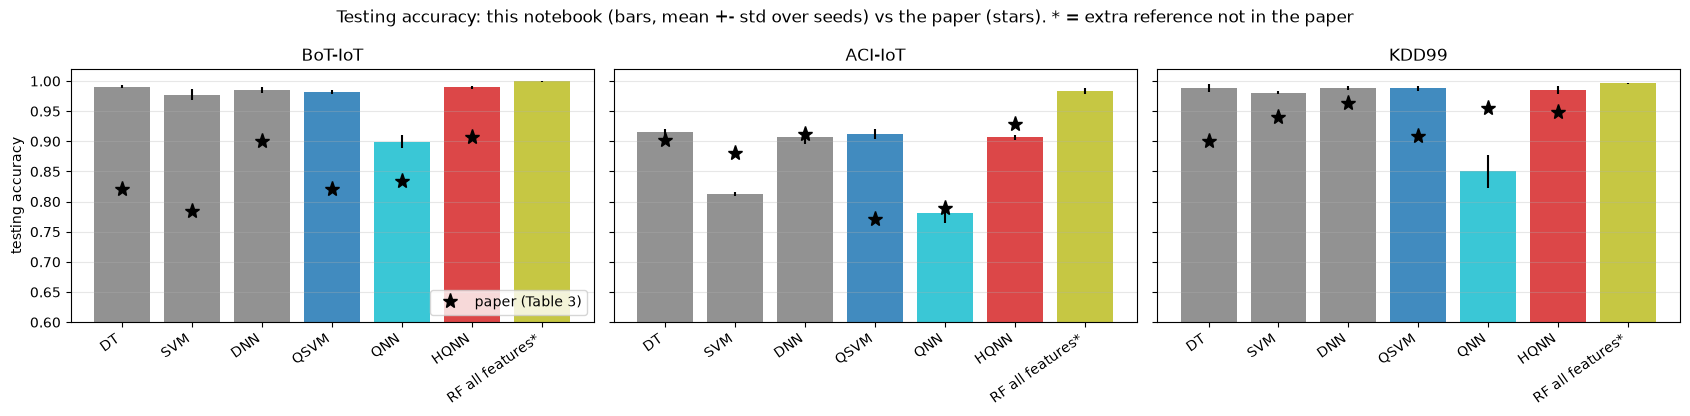

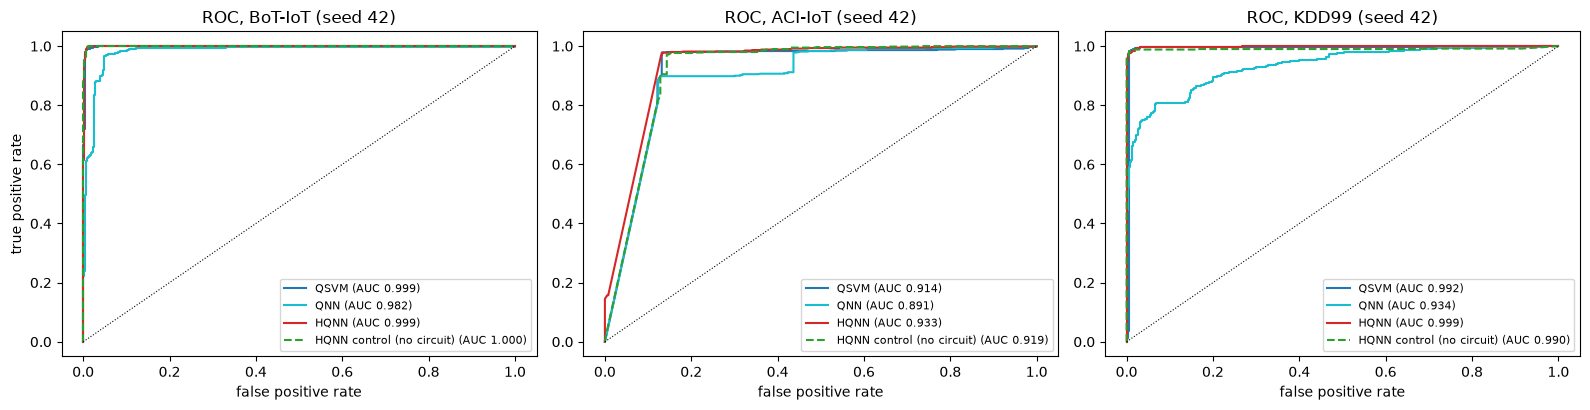

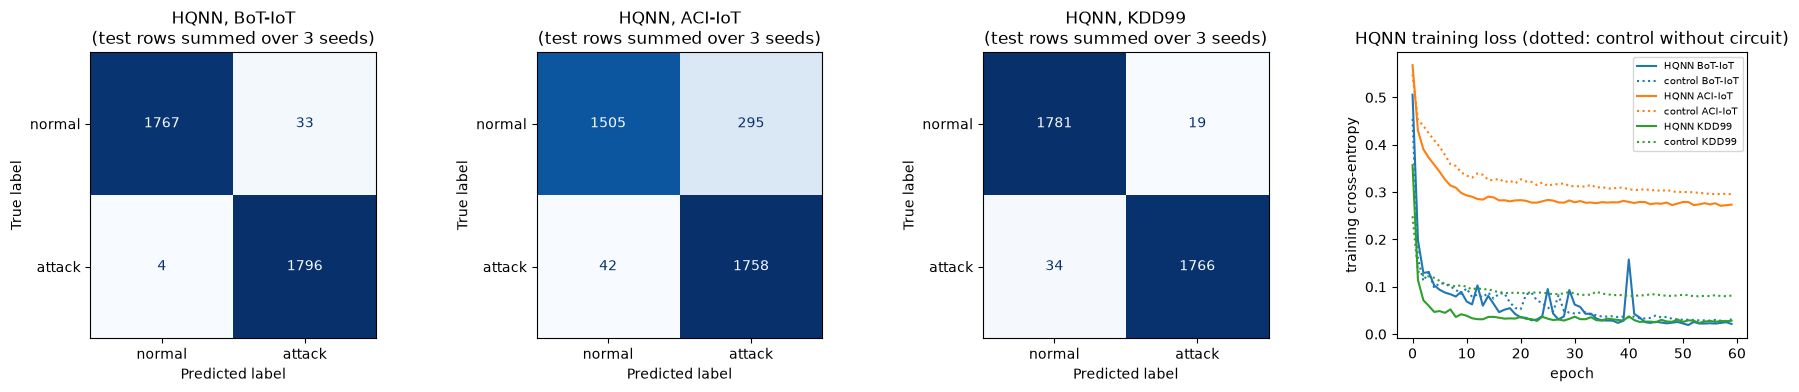

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
shown = MODEL_ORDER + ["RF all features (extra)"]
for ax, ds in zip(axs, DATASETS):
    g = res[res.dataset == ds].groupby("model").test_acc
    m, s = g.mean().loc[shown], g.std(ddof=0).loc[shown]
    ax.bar(range(len(shown)), m, yerr=s, color=["tab:grey"] * 3 + ["tab:blue", "tab:cyan", "tab:red", "tab:olive"], alpha=.85)
    ax.plot([i for i, k in enumerate(shown) if (ds, k) in PAPER], [PAPER[(ds, k)][1] for k in shown if (ds, k) in PAPER], "k*", ms=11, label="paper (Table 3)")
    ax.set_xticks(range(len(shown))); ax.set_xticklabels([k.replace(" (extra)", "*") for k in shown], rotation=35, ha="right")
    ax.set_title(ds); ax.set_ylim(0.6, 1.02); ax.grid(axis="y", alpha=.3)
axs[0].set_ylabel("testing accuracy"); axs[0].legend(loc="lower right")
plt.suptitle("Testing accuracy: this notebook (bars, mean +- std over seeds) vs the paper (stars). * = extra reference not in the paper"); plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, ds in zip(axs, DATASETS):
    for m, c in [("QSVM", "tab:blue"), ("QNN", "tab:cyan"), ("HQNN", "tab:red"), ("HQNN control (no circuit)", "tab:green")]:
        e = STORE[(ds, m)][0]; fpr, tpr, _ = roc_curve(e["y"], e["score"])
        ax.plot(fpr, tpr, color=c, ls="--" if "control" in m else "-", label=f"{m} (AUC {roc_auc_score(e['y'], e['score']):.3f})")
    ax.plot([0, 1], [0, 1], "k:", lw=.8); ax.set_title(f"ROC, {ds} (seed {SEED})"); ax.set_xlabel("false positive rate"); ax.legend(fontsize=8, loc="lower right")
axs[0].set_ylabel("true positive rate"); plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 4, figsize=(18, 4))
for ax, ds in zip(axs[:3], DATASETS):
    yy = np.concatenate([e["y"] for e in STORE[(ds, "HQNN")]]); pp = np.concatenate([e["pred"] for e in STORE[(ds, "HQNN")]])
    ConfusionMatrixDisplay(confusion_matrix(yy, pp), display_labels=["normal", "attack"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"HQNN, {ds}\n(test rows summed over {N_SEEDS} seeds)")
for ds, c in zip(DATASETS, ["tab:blue", "tab:orange", "tab:green"]):
    axs[3].plot(CURVES[(ds, SEED, "HQNN")], color=c, label=f"HQNN {ds}"); axs[3].plot(CURVES[(ds, SEED, "control")], color=c, ls=":", label=f"control {ds}")
axs[3].set_xlabel("epoch"); axs[3].set_ylabel("training cross-entropy"); axs[3].set_title("HQNN training loss (dotted: control without circuit)"); axs[3].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 10. How many qubits? The PCA-dimension study (Fig. 6)

The paper sweeps the number of retained features k from 1 to 8 and says accuracy stabilises above k = 5. Here the k features with
the largest PC1 loading are fed to an RBF-SVM and to the QSVM (bandwidth 1, C = 1, no tuning) on one seed. The claim we test is
"going from 5 to 6, 7 or 8 features gains at most one accuracy point".

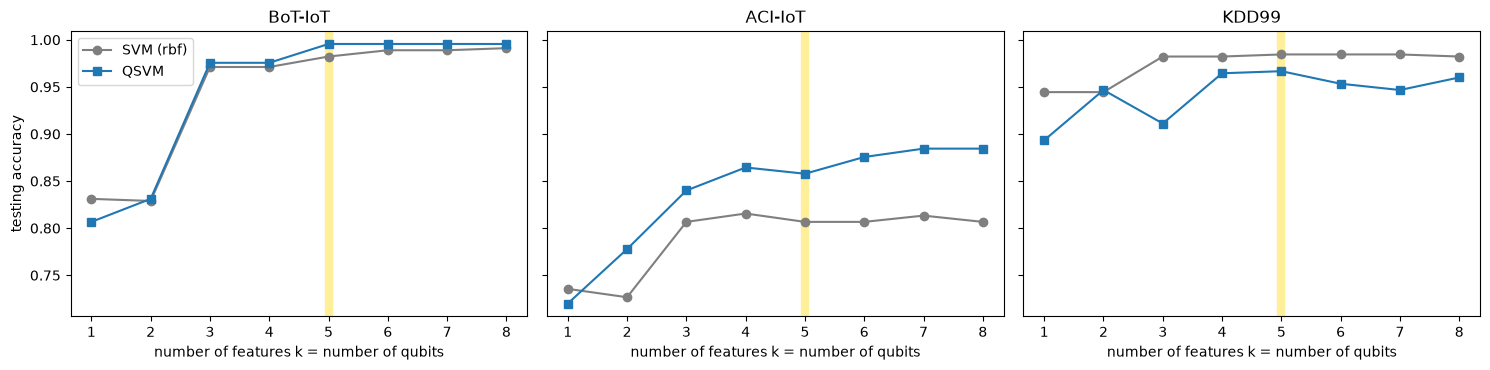

dataset,QSVM ACI-IoT,QSVM BoT-IoT,QSVM KDD99,SVM ACI-IoT,SVM BoT-IoT,SVM KDD99
k,,,,,,
1,0.720,0.807,0.893,0.736,0.831,0.944
2,0.778,0.831,0.947,0.727,0.829,0.944
3,0.840,0.976,0.911,0.807,0.971,0.982
4,0.864,0.976,0.964,0.816,0.971,0.982
5,0.858,0.996,0.967,0.807,0.982,0.984
6,0.876,0.996,0.953,0.807,0.989,0.984
7,0.884,0.996,0.947,0.813,0.989,0.984
8,0.884,0.996,0.960,0.807,0.991,0.982


In [16]:
KS, ksw = list(range(1, 9)), []
for ds in DATASETS:
    D = prepare(ds, SEED, k=8, pool_n=KSWEEP_N); Fa, y, tr, te = D["F"], D["y"], D["tr"], D["te"]
    for k in KS:
        Fk = Fa[:, :k]
        svm = SVC(kernel="rbf", C=1.0).fit(Fk[tr], y[tr]).score(Fk[te], y[te])
        S = zz_states(Fk); K = fidelity_kernel(S, S)
        qsvm = SVC(kernel="precomputed", C=1.0).fit(K[np.ix_(tr, tr)], y[tr]).score(K[np.ix_(te, tr)], y[te])
        ksw.append(dict(dataset=ds, k=k, SVM=svm, QSVM=qsvm))
ksw = pd.DataFrame(ksw)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, ds in zip(axs, DATASETS):
    d = ksw[ksw.dataset == ds]; ax.plot(d.k, d.SVM, "o-", color="tab:grey", label="SVM (rbf)"); ax.plot(d.k, d.QSVM, "s-", color="tab:blue", label="QSVM")
    ax.axvline(5, color="gold", lw=6, alpha=.4, zorder=0); ax.set_title(ds); ax.set_xlabel("number of features k = number of qubits")
axs[0].set_ylabel("testing accuracy"); axs[0].legend(); plt.tight_layout(); plt.show()
display(ksw.pivot(index="k", columns="dataset", values="QSVM").round(3).add_prefix("QSVM ").join(ksw.pivot(index="k", columns="dataset", values="SVM").round(3).add_prefix("SVM ")))

## 11. The repetition code (Section 4.6, Figs. 8 to 10)

The paper protects the encoded features with a **repetition code** and reports a "97 % success rate" over 80, 100 and 120 trials,
without saying which noise was applied. We implement the textbook **3-qubit bit-flip repetition code** on each of the five data
qubits (15 qubits in total): after the ZZ encoding each data qubit is copied to two helper qubits with CNOTs, an idle step in which
every physical qubit suffers a bit flip with probability `p` follows, and a majority vote (two CNOTs and a Toffoli) decodes. A trial
*succeeds* when the encoded circuit followed by its inverse returns to the all-zero string, which is exactly what happens without noise.
The unprotected circuit gets the same flips on its five qubits. The expected success rates are `(1-p)^5` without the code and
`(1 - 3p^2 + 2p^3)^5` with it.

noiseless sanity check (p = 0): unprotected 1.0 | protected 1.0


bit-flip probability p = 0.05; success rate in % (mean over 10 encoded flows, each run for 80/100/120 trials)
theory at p = 0.05: no code 77.4 % | repetition code 96.4 %


code            no code  repetition code
dataset trials                          
ACI-IoT 80         79.5             95.4
        100        79.9             95.5
        120        79.2             94.8
BoT-IoT 80         81.9             95.7
        100        82.3             95.9
        120        81.5             95.2
KDD99   80         82.0             95.7
        100        82.4             95.9
        120        81.7             95.3

measured                  theory                
code  no code repetition code no code repetition code
p                                                    
0.01     97.6           100.0    95.1            99.9
0.02     93.5           100.0    90.4            99.4
0.05     81.6            95.8    77.4            96.4
0.10     64.9            89.4    59.0            86.8
0.20     40.5            59.9    32.8            57.7

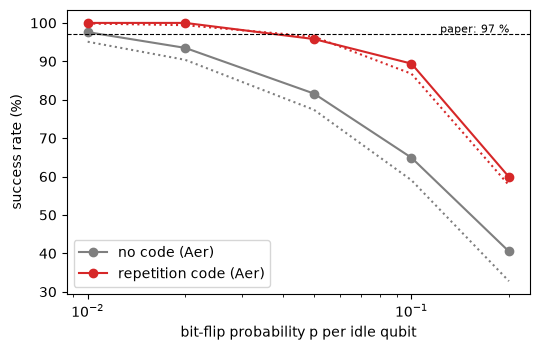

In [17]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, pauli_error

def rep_circuit(x, protected):
    n = len(x); fm = zz_feature_map(n, reps=ZZ_REPS, entanglement="linear").assign_parameters(x)
    qc = QuantumCircuit(3 * n if protected else n, n)
    qc.compose(fm, range(n), inplace=True)
    if protected:
        for i in range(n): qc.cx(i, n + 2 * i); qc.cx(i, n + 2 * i + 1)             # encode: alpha|0>+beta|1> -> alpha|000>+beta|111>
    qc.barrier()
    for q in range(qc.num_qubits): qc.id(q)                                           # the idle step where the noise acts
    qc.barrier()
    if protected:
        for i in range(n): qc.cx(i, n + 2 * i); qc.cx(i, n + 2 * i + 1); qc.ccx(n + 2 * i, n + 2 * i + 1, i)   # decode + majority vote
    qc.compose(fm.inverse(), range(n), inplace=True)
    qc.measure(range(n), range(n))
    return qc

def rep_success(x, p, trials, protected, seed):
    nm = NoiseModel(); nm.add_all_qubit_quantum_error(pauli_error([("X", p), ("I", 1 - p)]), ["id"])
    sim = AerSimulator(noise_model=nm, seed_simulator=seed)
    counts = sim.run(transpile(rep_circuit(x, protected), sim, optimization_level=0), shots=trials).result().get_counts()
    return counts.get("0" * len(x), 0) / trials

x0 = prepare("BoT-IoT", SEED)["F"][prepare("BoT-IoT", SEED)["te"][0]]
print("noiseless sanity check (p = 0): unprotected", rep_success(x0, 0.0, 50, False, SEED), "| protected", rep_success(x0, 0.0, 50, True, SEED))

P_MAIN, rep_rows = 0.05, []                  # CHOICE: the paper does not give the noise level; 5 % bit-flip probability per idle qubit
for ds in DATASETS:
    D = prepare(ds, SEED); r = np.random.default_rng(SEED); pts = D["F"][D["te"][r.choice(len(D["te"]), REP_REPEATS, replace=False)]]
    for trials in (80, 100, 120):
        for prot in (False, True):
            v = [rep_success(x, P_MAIN, trials, prot, SEED + i) for i, x in enumerate(pts)]
            rep_rows.append(dict(dataset=ds, trials=trials, code="repetition code" if prot else "no code", success=np.mean(v) * 100, std=np.std(v) * 100))
rep_df = pd.DataFrame(rep_rows); rep_pivot = rep_df.pivot_table(index=["dataset", "trials"], columns="code", values="success").round(1)
print(f"bit-flip probability p = {P_MAIN}; success rate in % (mean over {REP_REPEATS} encoded flows, each run for 80/100/120 trials)")
print(f"theory at p = {P_MAIN}: no code {(1 - P_MAIN) ** 5 * 100:.1f} % | repetition code {(1 - 3 * P_MAIN ** 2 + 2 * P_MAIN ** 3) ** 5 * 100:.1f} %")
display(rep_pivot)

sweep = []
for p in (0.01, 0.02, 0.05, 0.1, 0.2):
    D = prepare("BoT-IoT", SEED); pts = D["F"][D["te"][:REP_REPEATS]]
    for prot in (False, True):
        sweep.append(dict(p=p, code="repetition code" if prot else "no code", measured=100 * np.mean([rep_success(x, p, 100, prot, SEED + i) for i, x in enumerate(pts)]),
                          theory=100 * ((1 - 3 * p ** 2 + 2 * p ** 3) ** 5 if prot else (1 - p) ** 5)))
sweep = pd.DataFrame(sweep); display(sweep.pivot(index="p", columns="code", values=["measured", "theory"]).round(1))
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for c, col in [("no code", "tab:grey"), ("repetition code", "tab:red")]:
    d = sweep[sweep.code == c]; ax.plot(d.p, d.measured, "o-", color=col, label=c + " (Aer)"); ax.plot(d.p, d.theory, ":", color=col)
ax.axhline(97, color="k", lw=.8, ls="--"); ax.text(0.2, 97.5, "paper: 97 %", ha="right", fontsize=8)
ax.set_xlabel("bit-flip probability p per idle qubit"); ax.set_ylabel("success rate (%)"); ax.set_xscale("log"); ax.legend(); plt.tight_layout(); plt.show()

## 12. Does the preprocessing choice matter? (ablations)

Two choices the paper leaves open, tested on one seed for all three datasets: (a) the signed-log taming of heavy-tailed features
(`LOG_TAME`) and (b) "top-5 PC1 loadings" versus "projection on the first five components". SVM, Random Forest and QSVM are trained
on each variant; the HQNN is trained for the main variant (section 9) and the projection variant only, to save time.

In [18]:
ABL = [("top-5 PC1 loadings, log (main)", dict(variant="pc1_top5", log=True)),
       ("top-5 PC1 loadings, no log", dict(variant="pc1_top5", log=False)),
       ("projection on 5 PCs, log", dict(variant="pca_proj", log=True))]
abl = []
for ds in DATASETS:
    for label, kw in ABL:
        D = prepare(ds, SEED, **kw); Fa, y, tr, te = D["F"], D["y"], D["tr"], D["te"]
        row = {"dataset": ds, "variant": label,
               "SVM": SVC().fit(Fa[tr], y[tr]).score(Fa[te], y[te]),
               "RF": RandomForestClassifier(200, random_state=SEED, n_jobs=2).fit(Fa[tr], y[tr]).score(Fa[te], y[te])}
        _, p2, _, _, _ = fit_qsvm(Fa, y, tr, te, SEED); row["QSVM"] = accuracy_score(y[te], p2)
        if "main" in label:                                                       # already trained in section 8 (same seed)
            row["HQNN"] = float(res[(res.dataset == ds) & (res.model == "HQNN") & (res.seed == SEED)].test_acc.iloc[0])
        elif kw["log"]:                                                           # HQNN only for the projection variant (time)
            _, p2, _, _, _ = fit_hqnn(Fa, y, tr, te, SEED, True); row["HQNN"] = accuracy_score(y[te], p2)
        else:
            row["HQNN"] = np.nan
        abl.append(row)
abl = pd.DataFrame(abl).set_index(["dataset", "variant"]); display(abl.round(3))

SVM     RF   QSVM   HQNN
dataset variant                                                   
BoT-IoT top-5 PC1 loadings, log (main)  0.988  0.992  0.988  0.993
        top-5 PC1 loadings, no log      0.930  0.993  0.981    NaN
        projection on 5 PCs, log        0.999  0.999  0.998  0.998
ACI-IoT top-5 PC1 loadings, log (main)  0.810  0.923  0.923  0.912
        top-5 PC1 loadings, no log      0.794  0.953  0.811    NaN
        projection on 5 PCs, log        0.864  0.966  0.956  0.923
KDD99   top-5 PC1 loadings, log (main)  0.981  0.996  0.987  0.984
        top-5 PC1 loadings, no log      0.962  0.968  0.966    NaN
        projection on 5 PCs, log        0.980  0.988  0.988  0.990

## 13. Training time (Fig. 17)

The paper reports that the HQNN trains 29 % to 72 % faster than DT, SVM and DNN when simulated, and also faster on a quantum
computer. Our timings are wall-clock fit-plus-predict on the same machine: the classical models are scikit-learn on 5 features, the
HQNN is a state-vector simulation in PyTorch (training time per model includes, for QSVM, the bandwidth search). We report how many
times *longer* the HQNN takes than each classical model; the paper's claim would need this ratio to be below 1.

model,DT,SVM,DNN,QSVM,QNN,HQNN,HQNN control (no circuit)
dataset,,,,,,,
ACI-IoT,0.006,0.423,5.441,2.694,3.822,160.135,6.579
BoT-IoT,0.010,0.181,5.998,2.345,4.495,199.351,10.052
KDD99,0.008,0.074,3.342,2.246,3.443,160.753,5.889


HQNN simulation time divided by the classical model's time (x slower), ours:


,DT,SVM,DNN
BoT-IoT,19082.0,1100.0,33.0
ACI-IoT,25478.0,378.0,29.0
KDD99,20606.0,2170.0,48.0


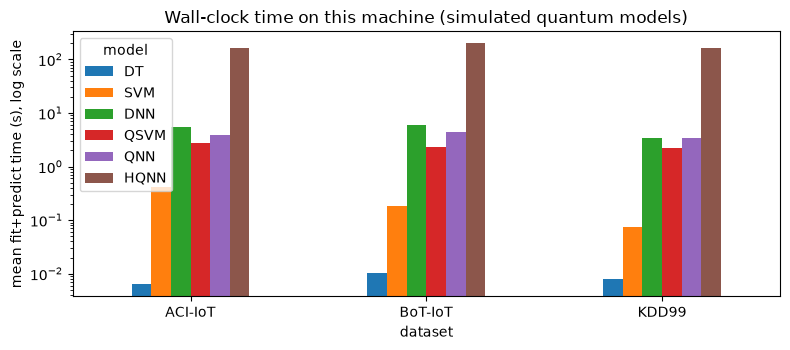

In [19]:
tt = res.groupby(["dataset", "model"]).time_s.mean().unstack()
PAPER_IMPR = {"BoT-IoT": {"DT": 65.42, "SVM": 66.57, "DNN": 72.24}, "ACI-IoT": {"DT": 53.48, "SVM": 56.14, "DNN": 68.34},
              "KDD99": {"DT": 29.08, "SVM": 27.86, "DNN": 31.89}}            # simulator improvements quoted in Section 5
impr = pd.DataFrame({ds: {m: 100 * (tt.loc[ds, m] - tt.loc[ds, "HQNN"]) / tt.loc[ds, m] for m in ("DT", "SVM", "DNN")} for ds in DATASETS}).T
slow = pd.DataFrame({ds: {m: tt.loc[ds, "HQNN"] / tt.loc[ds, m] for m in ("DT", "SVM", "DNN")} for ds in DATASETS}).T
display(tt[MODEL_ORDER + ["HQNN control (no circuit)"]].round(3)); print("HQNN simulation time divided by the classical model's time (x slower), ours:"); display(slow.round(0))
ax = tt[MODEL_ORDER].plot.bar(figsize=(8, 3.6), logy=True, rot=0); ax.set_ylabel("mean fit+predict time (s), log scale"); ax.set_title("Wall-clock time on this machine (simulated quantum models)")
plt.tight_layout(); plt.show()

## 14. Side by side with the paper

Verdict rules: an accuracy-type number is *reproduced* when it is within 0.02 of the paper's value, otherwise *not reached* (below)
or *exceeded* (above) with the gap. Statements about rankings are *reproduced* when the same ordering holds here. Claims that need
hardware or information the paper does not give are *cannot be checked*. Because the datasets are substitutes and the samples are
small, a match or a mismatch is evidence about the method, not a replication of the exact numbers.

In [20]:
def verdict(paper, ours, tol=TOL_ACC):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.3f})" if d > 0 else f"not reached ({d:.3f})")

mean = res.groupby(["dataset", "model"])[["train_acc", "test_acc", "precision", "recall", "f1"]].mean()
sd = res.groupby(["dataset", "model"])[["test_acc"]].std(ddof=0)
rows = []
for ds in DATASETS:
    for m in MODEL_ORDER:
        rows.append((f"{ds}: {m} testing accuracy", PAPER[(ds, m)][1], f"{mean.loc[(ds, m), 'test_acc']:.3f} +- {sd.loc[(ds, m), 'test_acc']:.3f}",
                     verdict(PAPER[(ds, m)][1], mean.loc[(ds, m), "test_acc"])))
for ds in DATASETS:
    for col, i, nm in [("precision", 3, "precision"), ("recall", 4, "recall"), ("f1", 5, "F1")]:
        rows.append((f"{ds}: HQNN {nm}", PAPER[(ds, "HQNN")][i], f"{mean.loc[(ds, 'HQNN'), col]:.3f}", verdict(PAPER[(ds, "HQNN")][i], mean.loc[(ds, "HQNN"), col])))
acc = mean["test_acc"].unstack()
for ds in DATASETS:
    p_q = PAPER[(ds, "HQNN")][1] > max(PAPER[(ds, "QSVM")][1], PAPER[(ds, "QNN")][1]); o_q = acc.loc[ds, "HQNN"] > max(acc.loc[ds, "QSVM"], acc.loc[ds, "QNN"])
    p_a = PAPER[(ds, "HQNN")][1] > max(PAPER[(ds, m)][1] for m in ("DT", "SVM", "DNN", "QSVM", "QNN"))
    o_a = acc.loc[ds, "HQNN"] > acc.loc[ds, ["DT", "SVM", "DNN", "QSVM", "QNN"]].max()
    rows.append((f"{ds}: HQNN is the most accurate quantum model", "yes" if p_q else "no (Table 3)", "yes" if o_q else "no", "reproduced" if p_q == o_q else "not reached"))
    rows.append((f"{ds}: HQNN beats all five other models", "yes" if p_a else "no (Table 3)", "yes" if o_a else "no", "reproduced" if p_a == o_a else "not reached"))
n_hq = sum(acc.loc[ds, "HQNN"] > acc.loc[ds, ["DT", "SVM", "DNN", "QSVM", "QNN"]].max() for ds in DATASETS)
rows.append(("headline: HQNN outperforms classical and quantum baselines on all datasets", "3 of 3 claimed (Table 3 itself shows 2 of 3)", f"{n_hq} of 3", "reproduced" if n_hq == 3 else "not reached"))
ctrl = (acc["HQNN"] - acc["HQNN control (no circuit)"]).mean()
rows.append(("(extra) circuit adds accuracy beyond the classical bottleneck control", "implied", f"{ctrl:+.3f} accuracy (HQNN minus control, mean of 3 datasets)", "n/a (our control, not a paper claim)"))
for ds in DATASETS:
    d = ksw[ksw.dataset == ds].set_index("k")
    g_s, g_q = d.loc[6:, "SVM"].max() - d.loc[5, "SVM"], d.loc[6:, "QSVM"].max() - d.loc[5, "QSVM"]
    rows.append((f"{ds}: k = 5 is where accuracy saturates (gain from k = 6..8 at most 0.01)", "marginal gain only (Fig. 6)", f"SVM {g_s:+.3f}, QSVM {g_q:+.3f}", "reproduced" if max(g_s, g_q) <= 0.01 else "not reached"))
r5 = rep_df[(rep_df.code == "repetition code")].success.mean(); r0 = rep_df[(rep_df.code == "no code")].success.mean()
rows.append(("repetition code success rate 97 % (80/100/120 trials, 3 datasets)", "97 %", f"{r5:.1f} % with code, {r0:.1f} % without (p = {P_MAIN})",
             "cannot be checked (noise level not given; matches only for p of about 0.05 or less)"))
for ds in DATASETS:
    for m in ("DT", "SVM", "DNN"):
        rows.append((f"{ds}: HQNN simulator training time shorter than {m}", f"{PAPER_IMPR[ds][m]:.1f} % shorter", f"{slow.loc[ds, m]:,.0f}x longer",
                     "reproduced" if impr.loc[ds, m] >= PAPER_IMPR[ds][m] - 10 else f"not reached (HQNN {slow.loc[ds, m]:,.0f}x slower, not faster)"))
rows.append(("results and speed-ups on a real quantum computer (AWS Braket)", "Figs. 8-10, 17", "not run", "cannot be checked"))
rows.append(("ROUT-4-2023 RPL routing-attack dataset", "Table 1", "replaced by KDD (see table at the top)", "cannot be checked"))
cmp_df = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
display(cmp_df)
kinds = cmp_df.verdict.str.extract(r"^(reproduced|exceeded|not reached|cannot be checked|n/a)")[0].fillna("other")
print("verdict counts:", kinds.value_counts().to_dict())

,claim,paper,this notebook,verdict
0,BoT-IoT: DT testing accuracy,0.821,0.991 +- 0.002,exceeded (+0.170)
1,BoT-IoT: SVM testing accuracy,0.784,0.977 +- 0.009,exceeded (+0.193)
2,BoT-IoT: DNN testing accuracy,0.901,0.986 +- 0.005,exceeded (+0.085)
3,BoT-IoT: QSVM testing accuracy,0.821,0.982 +- 0.004,exceeded (+0.161)
4,BoT-IoT: QNN testing accuracy,0.835,0.899 +- 0.011,exceeded (+0.064)
5,BoT-IoT: HQNN testing accuracy,0.907,0.990 +- 0.003,exceeded (+0.083)
6,ACI-IoT: DT testing accuracy,0.903,0.915 +- 0.005,reproduced
7,ACI-IoT: SVM testing accuracy,0.881,0.813 +- 0.003,not reached (-0.068)
8,ACI-IoT: DNN testing accuracy,0.912,0.906 +- 0.011,reproduced
9,ACI-IoT: QSVM testing accuracy,0.771,0.912 +- 0.008,exceeded (+0.141)


verdict counts: {'not reached': 19, 'reproduced': 14, 'exceeded': 13, 'cannot be checked': 3, 'n/a': 1}


## 15. Reading the paper critically

* **The datasets are not the ones in Table 1.** Table 1 names a third dataset, ROUT-4-2023 (RPL routing attacks, 494,021 rows),
  but the text, Table 2 and every figure use the KDD Cup 99 features, and 494,021 is the size of the 10 % KDD file. The "BoT-IoT"
  features of Table 2 (`HH_jit_L0.1_variance`, `MI_dir_L0.1_variance`, ...) are damped-window Kitsune/N-BaIoT-style statistics, not
  columns of the UNSW Bot-IoT release. Both 1,048,575-row datasets have exactly the row limit of a spreadsheet, so they were probably
  truncated in Excel, which silently keeps only the first million rows.
* **Duplicates and leakage.** The KDD 10 % file is about 70 % exact duplicates; without removing them, copies of one record sit on both
  sides of the 70/30 split. The paper does not say whether duplicates were removed.
* **PCA is used in two incompatible ways.** The text keeps the original features with the largest loading on the first component
  (Table 2), Eq. 6 projects on the top-k components. These give different features and different accuracies (section 12), and our top-5 loadings
  do not coincide with Table 2.
* **k was chosen by looking at test accuracy.** Section 4.5 picks k = 5 from classification accuracy over k = 1 to 8; unless a
  validation split was used, that is selection on the test set. With 5 features already saturating, the choice is harmless here.
* **The comparison is not like for like.** The classical models receive no tuning and have no stated hyper-parameters; a Random Forest on all
  features reaches 0.97 to 1.00 here on every dataset (section 9), above all models of the paper. Reducing everything to five features is a
  limit of the qubit count, not a property of the problem.
* **No seeds, no spread.** Table 3 gives a single number per cell. Differences of one or two points, the size of the gaps between
  HQNN, QNN and DNN, are within the seed-to-seed spread measured in section 9.
* **No quantum control.** An HQNN is a classical network with a small circuit in the middle. The control model of section 7 replaces the circuit
  by `tanh`; the comparison in section 14 shows how much of the accuracy the circuit explains.
* **The repetition code does not do what the text implies.** It corrects bit flips only, so phase noise (the dominant error in
  superconducting devices) passes through. The "97 %" depends entirely on the unstated flip probability (section 11) and has no
  effect on classification accuracy in a noiseless simulation.
* **Timing.** A state-vector simulation of a quantum circuit cannot be faster than a decision tree on five features, and our
  measurements confirm it by orders of magnitude; the percentages in Fig. 17 are not explained by the method. Hardware timings
  also include queue and shot costs the paper does not discuss.
* **Table 3 contradicts itself.** The next cell tests the table against elementary identities.

In [21]:
chk = []
for (ds, m), (trn, tst, err, P, R, F1v) in PAPER.items():
    f1_calc = 2 * P * R / (P + R); acc_floor = 1 - (R * (1 - P) / P + (1 - R))       # worst case when the positives fill the whole test set
    issues = []
    if abs(err - (1 - tst)) > 0.01: issues.append(f"error {err:.3f} but 1 - accuracy = {1 - tst:.3f}")
    if abs(F1v - f1_calc) > 0.01: issues.append(f"F1 {F1v:.3f} but 2PR/(P+R) = {f1_calc:.3f}")
    if tst < acc_floor - 0.005: issues.append(f"accuracy {tst:.3f} is below the minimum {acc_floor:.3f} that precision {P:.3f} and recall {R:.3f} allow")
    if issues: chk.append(dict(dataset=ds, model=m, problem="; ".join(issues)))
chk = pd.DataFrame(chk); print(f"{len(chk)} of {len(PAPER)} rows of Table 3 violate an identity:"); display(chk)

10 of 18 rows of Table 3 violate an identity:


,dataset,model,problem
0,BoT-IoT,SVM,error 0.172 but 1 - accuracy = 0.216; F1 0.739 but 2PR/(P+R) = 0.729
1,BoT-IoT,DNN,error 0.068 but 1 - accuracy = 0.099
2,BoT-IoT,QNN,F1 0.781 but 2PR/(P+R) = 0.814
3,BoT-IoT,HQNN,error 0.124 but 1 - accuracy = 0.093; accuracy 0.907 is below the minimum 0.958 that p...
4,ACI-IoT,DNN,error 0.188 but 1 - accuracy = 0.088
5,ACI-IoT,HQNN,error 0.204 but 1 - accuracy = 0.072
6,KDD99,DT,F1 0.910 but 2PR/(P+R) = 0.880
7,KDD99,QSVM,error 0.131 but 1 - accuracy = 0.091
8,KDD99,QNN,error 0.088 but 1 - accuracy = 0.044
9,KDD99,HQNN,error 0.041 but 1 - accuracy = 0.051; accuracy 0.949 is below the minimum 0.970 that p...


## 16. Exercises

1. Set `LOG_TAME = False` and rerun. Which dataset suffers most, and does the ranking HQNN > QNN > QSVM change?
2. Replace the closed CNOT chain in `variational` (and in `vqc_exact`, which must stay equal) by an open chain, or use 1 and 6 layers
   (`HQNN_LAYERS`). How do accuracy and training time change?
3. Replace `pi * torch.tanh(h)` by `torch.sigmoid(h) * 2 * np.pi`. Does the circuit still add anything over the control model?
4. Use `variant="pca_proj"` for the whole of section 8 (set `PCA_VARIANT`-style arguments in `prepare`) and compare Table 3 with the
   loading-based features of the paper.
5. In section 11 add phase-flip noise (`pauli_error([("Z", p), ("I", 1 - p)])`) next to the bit flips. What success rate does the repetition code
   reach now, and why?